# Phase 1: NDVI Generation from Zipped 8-Band Imagery

This notebook processes zipped Planet 8-band imagery from 2022, 2023, and 2024 to generate NDVI rasters.


**Expected runtime:** ~34 hours (can run unattended)

**Storage requirements:** ~140GB peak (one unzipped period + accumulating NDVI)

**Output:** ~24GB of NDVI rasters across all three years

## 1. Import Libraries and Setup Configuration

In [20]:
import rasterio
from rasterio.warp import calculate_default_transform, reproject, Resampling
from rasterio.mask import mask
from rasterio.io import MemoryFile
import numpy as np
import geopandas as gpd
from pathlib import Path
import zipfile
import shutil
import logging
from datetime import datetime
from concurrent.futures import ProcessPoolExecutor, as_completed
import warnings
warnings.filterwarnings('ignore')

print("✓ All packages loaded successfully!")

✓ All packages loaded successfully!


In [21]:
# ============================================================================
# CONFIGURATION - Modify these paths if needed
# ============================================================================

# Target coordinate system
TARGET_CRS = "EPSG:3400"  # NAD 1983 10TM AEP Forest

# Source directories for zipped imagery (one per year)
ZIP_SOURCES = {
    2022: Path(r"<PROJECT_ROOT>\workspace\planet_data\Ghost\2022\ndvi_analysis"),
    2023: Path(r"<PROJECT_ROOT>\workspace\planet_data\Ghost\2023\ndvi_analysis"),
    2024: Path(r"<PROJECT_ROOT>\workspace\planet_data\Ghost\2024\ndvi_analysis")
}

# Shapefile paths
AOI_SHAPEFILE = Path(r"S:\gis_layers\aoi\ghost_AOI.shp")

LANDCOVER_SHAPEFILES = {
    2022: Path(r"<PROJECT_ROOT>\workspace\gis_layers\strata_2022\herb_shrub_wetland_2022.shp"),
    2023: Path(r"<PROJECT_ROOT>\workspace\gis_layers\strata_2023\herb_shrub_wetland_2023.shp"),
    2024: Path(r"<PROJECT_ROOT>\workspace\gis_layers\strata_2024\herb_shrub_wetland_2024.shp")
}

# Output directories on fast SSD
BASE_OUTPUT = Path(r"S:\8band_processing_workflow")
TEMP_DIR = BASE_OUTPUT / "temp"
NDVI_RAW_DIR = BASE_OUTPUT / "ndvi_raw"

# Processing parameters
N_WORKERS = 8  # Number of parallel processes
RED_BAND = 6   # Band 6 is Red
NIR_BAND = 8   # Band 8 is NIR

print("✓ Configuration loaded")
print(f"  Output directory: {BASE_OUTPUT}")
print(f"  Parallel workers: {N_WORKERS}")

✓ Configuration loaded
  Output directory: S:\8band_processing_workflow
  Parallel workers: 8


## 2. Setup Logging and Directories

In [22]:
def setup_logging():
    """Configure logging to file and console"""
    log_file = BASE_OUTPUT / f"phase1_processing_{datetime.now().strftime('%Y%m%d_%H%M%S')}.log"
    
    logging.basicConfig(
        level=logging.INFO,
        format='%(asctime)s - %(levelname)s - %(message)s',
        handlers=[
            logging.FileHandler(log_file),
            logging.StreamHandler()
        ]
    )
    return logging.getLogger(__name__)

def create_output_directories():
    """Create all necessary output directories"""
    logger.info("Creating output directory structure...")
    
    # Create base directories
    TEMP_DIR.mkdir(parents=True, exist_ok=True)
    NDVI_RAW_DIR.mkdir(parents=True, exist_ok=True)
    
    # Create year-specific directories
    for year in [2022, 2023, 2024]:
        (NDVI_RAW_DIR / str(year)).mkdir(parents=True, exist_ok=True)
    
    logger.info(f"✓ Output directories created at {BASE_OUTPUT}")

# Initialize logging
logger = setup_logging()
create_output_directories()

print("✓ Logging and directories initialized")

2025-11-16 11:26:01,994 - INFO - Creating output directory structure...
2025-11-16 11:26:01,995 - INFO - ✓ Output directories created at S:\8band_processing_workflow


✓ Logging and directories initialized


## 3. Load and Verify Shapefiles

In [23]:
def verify_and_reproject_shapefile(shapefile_path, target_crs):
    """
    Load shapefile and reproject to target CRS if needed
    Returns GeoDataFrame in target CRS
    """
    logger.info(f"Loading shapefile: {shapefile_path.name}")
    
    gdf = gpd.read_file(shapefile_path)
    
    if gdf.crs is None:
        logger.warning(f"  ⚠ No CRS defined for {shapefile_path.name}")
        logger.warning(f"  Assuming it's already in {target_crs}")
        gdf.set_crs(target_crs, inplace=True)
    elif gdf.crs.to_string() != target_crs:
        logger.info(f"  Reprojecting from {gdf.crs.to_string()} to {target_crs}")
        gdf = gdf.to_crs(target_crs)
    else:
        logger.info(f"  ✓ Already in {target_crs}")
    
    return gdf

def load_shapefiles():
    """Load and verify all shapefiles"""
    logger.info("=" * 80)
    logger.info("LOADING AND VERIFYING SHAPEFILES")
    logger.info("=" * 80)
    
    # Load AOI shapefile
    aoi_gdf = verify_and_reproject_shapefile(AOI_SHAPEFILE, TARGET_CRS)
    
    # Load landcover shapefiles for each year
    landcover_gdfs = {}
    for year, lc_path in LANDCOVER_SHAPEFILES.items():
        landcover_gdfs[year] = verify_and_reproject_shapefile(lc_path, TARGET_CRS)
    
    logger.info("✓ All shapefiles loaded and verified")
    return aoi_gdf, landcover_gdfs

# Load shapefiles
aoi_gdf, landcover_gdfs = load_shapefiles()

print("\n✓ Shapefiles loaded successfully")
print(f"  AOI features: {len(aoi_gdf)}")
for year, gdf in landcover_gdfs.items():
    print(f"  {year} landcover features: {len(gdf)}")

2025-11-16 11:26:02,061 - INFO - ================================================================================
2025-11-16 11:26:02,062 - INFO - LOADING AND VERIFYING SHAPEFILES
2025-11-16 11:26:02,066 - INFO - ================================================================================
2025-11-16 11:26:02,068 - INFO - Loading shapefile: ghost_AOI.shp
2025-11-16 11:26:02,316 - INFO -   ✓ Already in EPSG:3400
2025-11-16 11:26:02,317 - INFO - Loading shapefile: herb_shrub_wetland_2022.shp
2025-11-16 11:26:05,493 - INFO -   Reprojecting from PROJCS["Lambert_Conformal_Conic_2SP",GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0],UNIT["Degree",0.0174532925199433]],PROJECTION["Lambert_Conformal_Conic_2SP"],PARAMETER["latitude_of_origin",49],PARAMETER["central_meridian",-95],PARAMETER["standard_parallel_1",49],PARAMETER["standard_parallel_2",77],PARAMETER["false_easting",0],


✓ Shapefiles loaded successfully
  AOI features: 1
  2022 landcover features: 3
  2023 landcover features: 3
  2024 landcover features: 3


## 4. Define NDVI Calculation Function

In [24]:
def calculate_ndvi_from_tif(tif_path, aoi_geom, landcover_geom, year):
    """
    Process a single 8-band TIF to NDVI with clipping and masking
    
    Workflow:
    1. Reproject shapefiles to source CRS
    2. Mask Red and NIR bands to AOI and landcover (in source CRS)
    3. Convert masked pixels to NaN before NDVI calculation
    4. Calculate NDVI only on valid pixels
    5. Reproject final NDVI to target CRS
    """
    try:
        tif_name = Path(tif_path).stem
        
        with rasterio.open(tif_path) as src:
            src_crs = src.crs
            
            # Reproject shapefiles to source CRS if needed
            if aoi_geom.crs.to_string() != src_crs.to_string():
                aoi_src_crs = aoi_geom.to_crs(src_crs)
            else:
                aoi_src_crs = aoi_geom
            
            if landcover_geom.crs.to_string() != src_crs.to_string():
                lc_src_crs = landcover_geom.to_crs(src_crs)
            else:
                lc_src_crs = landcover_geom
            
            # Read full Red and NIR bands
            red_full = src.read(RED_BAND)
            nir_full = src.read(NIR_BAND)
            
            # Create metadata
            meta = src.meta.copy()
            meta.update({'count': 1, 'dtype': 'float32', 'nodata': np.nan})
            
            # Mask Red band to AOI and landcover (in source CRS)
            with MemoryFile() as memfile:
                with memfile.open(**meta) as mem_dataset:
                    mem_dataset.write(red_full, 1)
                    
                    # First: AOI clip
                    aoi_shapes = [geom.__geo_interface__ for geom in aoi_src_crs.geometry]
                    red_aoi, transform_aoi = mask(
                        mem_dataset,
                        aoi_shapes,
                        crop=True,
                        filled=False,
                        nodata=np.nan
                    )
                    
                    # Update meta for AOI-clipped extent
                    meta_aoi = meta.copy()
                    meta_aoi.update({
                        'height': red_aoi.shape[1],
                        'width': red_aoi.shape[2],
                        'transform': transform_aoi
                    })
            
            # Apply same AOI clip to NIR
            with MemoryFile() as memfile:
                with memfile.open(**meta) as mem_dataset:
                    mem_dataset.write(nir_full, 1)
                    
                    aoi_shapes = [geom.__geo_interface__ for geom in aoi_src_crs.geometry]
                    nir_aoi, _ = mask(
                        mem_dataset,
                        aoi_shapes,
                        crop=True,
                        filled=False,
                        nodata=np.nan
                    )
            
            # Apply landcover mask to both (crop=False to keep same extent)
            with MemoryFile() as memfile:
                with memfile.open(**meta_aoi) as mem_dataset:
                    mem_dataset.write(red_aoi)
                    
                    lc_shapes = [geom.__geo_interface__ for geom in lc_src_crs.geometry]
                    red_masked, transform_masked = mask(
                        mem_dataset,
                        lc_shapes,
                        crop=False,
                        filled=False,
                        nodata=np.nan,
                        invert=False
                    )
            
            with MemoryFile() as memfile:
                with memfile.open(**meta_aoi) as mem_dataset:
                    mem_dataset.write(nir_aoi)
                    
                    lc_shapes = [geom.__geo_interface__ for geom in lc_src_crs.geometry]
                    nir_masked, _ = mask(
                        mem_dataset,
                        lc_shapes,
                        crop=False,
                        filled=False,
                        nodata=np.nan,
                        invert=False
                    )
            
            # Extract arrays and convert masked pixels to NaN
            red_arr = red_masked[0]
            nir_arr = nir_masked[0]
            
            # CRITICAL: Convert masked arrays to regular arrays with NaN for masked values
            if np.ma.is_masked(red_arr):
                red_arr = red_arr.filled(np.nan)
            if np.ma.is_masked(nir_arr):
                nir_arr = nir_arr.filled(np.nan)
            
            # Calculate NDVI only on valid (non-NaN) pixels
            denominator = nir_arr + red_arr
            
            ndvi = np.where(
                (denominator != 0) & ~np.isnan(denominator),
                (nir_arr - red_arr) / denominator,
                np.nan
            )
            
            # Clip to valid NDVI range
            ndvi = np.clip(ndvi, -1, 1)
            
            # Update metadata for masked extent
            meta_masked = meta_aoi.copy()
            meta_masked.update({
                'dtype': 'float32',
                'nodata': np.nan,
                'transform': transform_masked
            })
            
            # Reproject NDVI to target CRS if needed
            if src_crs.to_string() != TARGET_CRS:
                transform_target, width_target, height_target = calculate_default_transform(
                    src_crs, TARGET_CRS, 
                    meta_masked['width'], meta_masked['height'],
                    *rasterio.transform.array_bounds(
                        meta_masked['height'],
                        meta_masked['width'],
                        meta_masked['transform']
                    )
                )
                
                ndvi_reproj = np.empty((height_target, width_target), dtype=np.float32)
                ndvi_reproj.fill(np.nan)  # Initialize with NaN
                
                reproject(
                    source=ndvi,
                    destination=ndvi_reproj,
                    src_transform=meta_masked['transform'],
                    src_crs=src_crs,
                    src_nodata=np.nan,
                    dst_transform=transform_target,
                    dst_crs=TARGET_CRS,
                    dst_nodata=np.nan,
                    resampling=Resampling.bilinear
                )
                
                ndvi_final = ndvi_reproj
                final_transform = transform_target
                final_width = width_target
                final_height = height_target
                final_crs = TARGET_CRS
            else:
                ndvi_final = ndvi
                final_transform = meta_masked['transform']
                final_width = meta_masked['width']
                final_height = meta_masked['height']
                final_crs = src_crs
            
            # Prepare output metadata
            output_meta = {
                'driver': 'GTiff',
                'dtype': 'float32',
                'nodata': np.nan,
                'width': final_width,
                'height': final_height,
                'count': 1,
                'crs': final_crs,
                'transform': final_transform,
                'compress': 'lzw',
                'tiled': True,
                'blockxsize': 256,
                'blockysize': 256,
                'BIGTIFF': 'IF_SAFER'
            }
            
            # Save output - ensure masked arrays are converted to NaN
            output_filename = f"NDVI_{tif_name}.tif"
            output_path = NDVI_RAW_DIR / str(year) / output_filename
            
            # Handle masked array if present
            if np.ma.is_masked(ndvi_final):
                ndvi_to_write = ndvi_final.filled(np.nan)
            else:
                ndvi_to_write = ndvi_final
            
            with rasterio.open(output_path, 'w', **output_meta) as dst:
                dst.write(ndvi_to_write, 1)
                dst.set_band_description(1, 'NDVI')
            
            return True, output_path
        
    except Exception as e:
        return False, f"Error processing {tif_path.name}: {str(e)}"

print("✓ NDVI calculation function defined")

✓ NDVI calculation function defined


## 5. Define Zip Processing Function

In [25]:
def process_zip_file(zip_path, aoi_gdf, landcover_gdf, year):
    """
    Extract and process all TIF files from a single zip archive
    Sequential processing to avoid Windows multiprocessing issues
    """
    stats = {
        'zip_name': zip_path.name,
        'total_images': 0,
        'successful': 0,
        'failed': 0,
        'errors': []
    }
    
    logger.info(f"\n{'='*80}")
    logger.info(f"Processing: {zip_path.name}")
    logger.info(f"{'='*80}")
    
    try:
        # Clear temp directory
        if TEMP_DIR.exists():
            shutil.rmtree(TEMP_DIR)
        TEMP_DIR.mkdir(parents=True, exist_ok=True)
        
        # Extract zip file
        logger.info("Extracting zip file...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(TEMP_DIR)
        
        # Find TIF folder at root level
        tif_folder = None
        
        for folder_name in ["files", "Files", "PSScene", "psscene"]:
            direct_path = TEMP_DIR / folder_name
            if direct_path.exists() and direct_path.is_dir():
                tif_folder = direct_path
                logger.info(f"Found TIF folder at root: {folder_name}")
                break
        
        if tif_folder is None:
            # Try nested structure as fallback
            for item in TEMP_DIR.iterdir():
                if item.is_dir():
                    for subfolder_name in ["PSScene", "psscene", "files", "Files"]:
                        potential_path = item / subfolder_name
                        if potential_path.exists():
                            tif_folder = potential_path
                            logger.info(f"Found TIF folder nested: {item.name}/{subfolder_name}")
                            break
                    if tif_folder is not None:
                        break
        
        if tif_folder is None:
            error_msg = f"Could not find PSScene or files folder in {zip_path.name}"
            logger.error(error_msg)
            stats['errors'].append(error_msg)
            return stats
        
        # Find all TIF files matching the pattern
        tif_files = sorted(list(tif_folder.glob("*_3B_AnalyticMS_SR_8b_harmonized.tif")))
        stats['total_images'] = len(tif_files)
        
        logger.info(f"Found {len(tif_files)} TIF files to process")
        
        if len(tif_files) == 0:
            logger.warning("No TIF files found matching pattern")
            return stats
        
        # Process TIFs SEQUENTIALLY (Windows-compatible)
        logger.info(f"Processing {len(tif_files)} images sequentially...")
        
        for i, tif_file in enumerate(tif_files, 1):
            try:
                success, result = calculate_ndvi_from_tif(
                    tif_file,
                    aoi_gdf,
                    landcover_gdf,
                    year
                )
                
                if success:
                    stats['successful'] += 1
                    logger.info(f"  ✓ [{i}/{len(tif_files)}] {tif_file.name}")
                else:
                    stats['failed'] += 1
                    stats['errors'].append(result)
                    logger.error(f"  ✗ [{i}/{len(tif_files)}] {result}")
                    
            except Exception as e:
                stats['failed'] += 1
                error_msg = f"Exception processing {tif_file.name}: {str(e)}"
                stats['errors'].append(error_msg)
                logger.error(f"  ✗ [{i}/{len(tif_files)}] {error_msg}")
        
        # Clean up temp directory
        logger.info("Cleaning up temporary files...")
        shutil.rmtree(TEMP_DIR)
        TEMP_DIR.mkdir(parents=True, exist_ok=True)
        
        logger.info(f"✓ Completed {zip_path.name}: {stats['successful']}/{stats['total_images']} successful")
        
    except Exception as e:
        error_msg = f"Fatal error processing {zip_path.name}: {str(e)}"
        logger.error(error_msg)
        stats['errors'].append(error_msg)
    
    return stats

print("✓ Fixed process_zip_file function loaded (sequential processing)")

✓ Fixed process_zip_file function loaded (sequential processing)


## 6. Run Main Processing

**This cell will take 7-8 hours to complete!**

It processes all zip files from 2022, 2023, and 2024 sequentially.

In [26]:
def process_all_years():
    """Main function to process all years"""
    
    logger.info("=" * 80)
    logger.info("PHASE 1: NDVI GENERATION FROM ZIPPED IMAGERY")
    logger.info("=" * 80)
    logger.info(f"Start time: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    logger.info("")
    
    # Overall statistics
    overall_stats = {
        'total_zips': 0,
        'successful_zips': 0,
        'failed_zips': 0,
        'total_images': 0,
        'successful_images': 0,
        'failed_images': 0
    }
    
    # Process each year
    for year in sorted(ZIP_SOURCES.keys()):
        logger.info(f"\n{'#'*80}")
        logger.info(f"# PROCESSING YEAR {year}")
        logger.info(f"{'#'*80}\n")
        
        zip_dir = ZIP_SOURCES[year]
        
        if not zip_dir.exists():
            logger.error(f"Directory not found: {zip_dir}")
            continue
        
        # Get all zip files, sorted chronologically
        zip_files = sorted(list(zip_dir.glob("*.zip")))
        
        if len(zip_files) == 0:
            logger.warning(f"No zip files found in {zip_dir}")
            continue
        
        logger.info(f"Found {len(zip_files)} zip files for year {year}")
        
        # Process each zip file
        for zip_file in zip_files:
            overall_stats['total_zips'] += 1
            
            stats = process_zip_file(
                zip_file,
                aoi_gdf,
                landcover_gdfs[year],
                year
            )
            
            overall_stats['total_images'] += stats['total_images']
            overall_stats['successful_images'] += stats['successful']
            overall_stats['failed_images'] += stats['failed']
            
            if stats['successful'] > 0:
                overall_stats['successful_zips'] += 1
            if stats['failed'] > 0 or len(stats['errors']) > 0:
                overall_stats['failed_zips'] += 1
    
    # Final summary
    logger.info("\n" + "=" * 80)
    logger.info("PROCESSING COMPLETE - FINAL SUMMARY")
    logger.info("=" * 80)
    logger.info(f"Total zip files processed: {overall_stats['total_zips']}")
    logger.info(f"  Successful: {overall_stats['successful_zips']}")
    logger.info(f"  Failed: {overall_stats['failed_zips']}")
    logger.info(f"\nTotal images processed: {overall_stats['total_images']}")
    logger.info(f"  Successful: {overall_stats['successful_images']}")
    logger.info(f"  Failed: {overall_stats['failed_images']}")
    logger.info(f"\nEnd time: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}")
    logger.info(f"Output location: {NDVI_RAW_DIR}")
    logger.info("=" * 80)
    
    return overall_stats

# RUN THE PROCESSING
print("Starting Phase 1 processing...")
print("This will take approximately 7-8 hours.")
print("Progress will be logged to console and file.\n")

results = process_all_years()

print("\n" + "="*80)
print("PHASE 1 COMPLETE!")
print("="*80)
print(f"Processed {results['successful_images']} images successfully")
print(f"Output saved to: {NDVI_RAW_DIR}")

2025-11-16 11:26:13,326 - INFO - ================================================================================
2025-11-16 11:26:13,331 - INFO - PHASE 1: NDVI GENERATION FROM ZIPPED IMAGERY
2025-11-16 11:26:13,345 - INFO - ================================================================================
2025-11-16 11:26:13,350 - INFO - Start time: 2025-11-16 11:26:13
2025-11-16 11:26:13,351 - INFO - 
2025-11-16 11:26:13,354 - INFO - 
################################################################################
2025-11-16 11:26:13,357 - INFO - # PROCESSING YEAR 2022
2025-11-16 11:26:13,364 - INFO - ################################################################################

2025-11-16 11:26:13,407 - INFO - Found 19 zip files for year 2022
2025-11-16 11:26:13,408 - INFO - 
2025-11-16 11:26:13,410 - INFO - Processing: Ghost_Aug14_2022_psscene_analytic_8b_sr_udm2.zip
2025-11-16 11:26:13,413 - INFO - ================================================================================
2

Starting Phase 1 processing...
This will take approximately 7-8 hours.
Progress will be logged to console and file.



In [ ]:
# Comprehensive Phase 1 Processing Check
import rasterio
from pathlib import Path
import pandas as pd
import numpy as np

print("="*80)
print("PHASE 1 PROCESSING VERIFICATION")
print("="*80)

# Check what was processed from the log file
log_files = list(BASE_OUTPUT.glob("phase1_processing_*.log"))
if log_files:
    latest_log = max(log_files, key=lambda p: p.stat().st_mtime)
    print(f"\nLatest log file: {latest_log.name}")
    
    # Parse log for summary statistics
    with open(latest_log, 'r') as f:
        log_content = f.read()
        
    # Extract final summary if present
    if "FINAL SUMMARY" in log_content:
        summary_start = log_content.find("FINAL SUMMARY")
        summary_section = log_content[summary_start:summary_start+1000]
        print("\n" + summary_section[:500])

# Now check the actual output files
results = {}

for year in [2022, 2023, 2024]:
    year_dir = NDVI_RAW_DIR / str(year)
    
    if not year_dir.exists():
        print(f"\n❌ {year}: Directory not found!")
        continue
    
    ndvi_files = list(year_dir.glob("NDVI_*.tif"))
    
    print(f"\n{'='*80}")
    print(f"YEAR {year}")
    print(f"{'='*80}")
    print(f"Total NDVI files created: {len(ndvi_files)}")
    
    # Get file sizes and dates from filenames
    file_info = []
    total_size = 0
    
    for f in ndvi_files:
        size_mb = f.stat().st_size / (1024**2)
        total_size += size_mb
        
        # Extract date from filename: NDVI_YYYYMMDD_HHMMSS_...
        parts = f.stem.split('_')
        if len(parts) >= 3:
            date_str = parts[1]  # YYYYMMDD
            try:
                from datetime import datetime
                date_obj = datetime.strptime(date_str, '%Y%m%d')
                file_info.append({
                    'filename': f.name,
                    'date': date_obj,
                    'size_mb': size_mb
                })
            except:
                pass
    
    print(f"Total storage: {total_size/1024:.2f} GB")
    
    if file_info:
        df = pd.DataFrame(file_info)
        df = df.sort_values('date')
        
        # Show date range
        print(f"\nDate range:")
        print(f"  First image: {df['date'].min().strftime('%Y-%m-%d')}")
        print(f"  Last image:  {df['date'].max().strftime('%Y-%m-%d')}")
        
        # Count images per month
        df['month'] = df['date'].dt.to_period('M')
        monthly_counts = df.groupby('month').size()
        
        print(f"\nImages per month:")
        for month, count in monthly_counts.items():
            print(f"  {month}: {count:3d} images")
        
        # File size statistics
        print(f"\nFile sizes:")
        print(f"  Min:  {df['size_mb'].min():.2f} MB")
        print(f"  Max:  {df['size_mb'].max():.2f} MB")
        print(f"  Mean: {df['size_mb'].mean():.2f} MB")
    
    results[year] = {
        'count': len(ndvi_files),
        'total_gb': total_size/1024,
        'files': ndvi_files
    }

# Overall summary
print(f"\n{'='*80}")
print("OVERALL SUMMARY")
print(f"{'='*80}")
total_files = sum(r['count'] for r in results.values())
total_storage = sum(r['total_gb'] for r in results.values())

print(f"Total NDVI files across all years: {total_files}")
print(f"Total storage used: {total_storage:.2f} GB")

print(f"\nBreakdown by year:")
for year in [2022, 2023, 2024]:
    if year in results:
        print(f"  {year}: {results[year]['count']:4d} files ({results[year]['total_gb']:6.2f} GB)")

# Quality check: Sample random files from each year
print(f"\n{'='*80}")
print("QUALITY CHECK: Sampling random NDVI files")
print(f"{'='*80}")

for year in [2022, 2023, 2024]:
    if year not in results or results[year]['count'] == 0:
        continue
    
    # Sample 3 random files
    import random
    sample_files = random.sample(results[year]['files'], min(3, len(results[year]['files'])))
    
    print(f"\n{year} - Checking {len(sample_files)} random files:")
    
    for ndvi_file in sample_files:
        with rasterio.open(ndvi_file) as src:
            ndvi = src.read(1, masked=True)
            
            valid_pixels = (~ndvi.mask).sum()
            total_pixels = ndvi.size
            pct_valid = (valid_pixels / total_pixels) * 100
            
            if valid_pixels > 0:
                ndvi_min = ndvi.min()
                ndvi_max = ndvi.max()
                ndvi_mean = ndvi.mean()
                
                # Check for suspicious values
                issues = []
                if valid_pixels < 100:
                    issues.append("Very few valid pixels!")
                if ndvi_mean < -0.5 or ndvi_mean > 0.95:
                    issues.append(f"Unusual mean NDVI: {ndvi_mean:.3f}")
                
                status = "⚠️ " + ", ".join(issues) if issues else "✓"
                
                print(f"  {status} {ndvi_file.name[:50]:50s}")
                print(f"      Valid pixels: {valid_pixels:8,} ({pct_valid:5.1f}%) | "
                      f"NDVI: [{ndvi_min:6.3f}, {ndvi_max:6.3f}] mean={ndvi_mean:6.3f}")
            else:
                print(f"  ❌ {ndvi_file.name[:50]:50s}")
                print(f"      NO VALID PIXELS - all masked!")

# Check for expected vs actual based on source zips
print(f"\n{'='*80}")
print("COMPARING TO SOURCE ZIP FILES")
print(f"{'='*80}")

for year in [2022, 2023, 2024]:
    zip_dir = ZIP_SOURCES[year]
    if zip_dir.exists():
        zip_files = list(zip_dir.glob("*.zip"))
        print(f"\n{year}:")
        print(f"  Source zip files: {len(zip_files)}")
        print(f"  NDVI files created: {results.get(year, {}).get('count', 0)}")
        
        # Estimate expected images (rough average)
        # This is just to flag if something seems very wrong
        if len(zip_files) > 0:
            avg_per_zip = results.get(year, {}).get('count', 0) / len(zip_files)
            print(f"  Average images per zip: {avg_per_zip:.1f}")
            
            if avg_per_zip < 5:
                print(f"  ⚠️  Low average - might indicate issues or small overlap")
            elif avg_per_zip > 200:
                print(f"  ⚠️  High average - seems unusual")

print(f"\n{'='*80}")
print("VERIFICATION COMPLETE")
print(f"{'='*80}")

PHASE 1 PROCESSING VERIFICATION

Latest log file: phase1_processing_20251114_215053.log

FINAL SUMMARY
2025-11-16 08:36:29,451 - INFO - ================================================================================
2025-11-16 08:36:29,455 - INFO - Total zip files processed: 44
2025-11-16 08:36:29,469 - INFO -   Successful: 44
2025-11-16 08:36:29,493 - INFO -   Failed: 9
2025-11-16 08:36:29,502 - INFO - 
Total images processed: 1609
2025-11-16 08:36:29,505 - INFO -   Successful: 1376
2025-11-16 08:36:29,515 - INFO -   Failed: 233
2025-11-16 08:36:29,532 - INFO - 
End time: 2025-11-

YEAR 2022
Total NDVI files created: 378
Total storage: 9.99 GB

Date range:
  First image: 2022-05-06
  Last image:  2022-10-18

Images per month:
  2022-05:  46 images
  2022-06:  36 images
  2022-07:  69 images
  2022-08:  85 images
  2022-09:  78 images
  2022-10:  64 images

File sizes:
  Min:  0.23 MB
  Max:  85.67 MB
  Mean: 27.06 MB

YEAR 2023
Total NDVI files created: 474
Total storage: 8.77 GB

Da

In [ ]:
# Check the log file for failure reasons
log_file = BASE_OUTPUT / "phase1_processing_20251114_215053.log"

print("Analyzing failures from log file...")
print("="*80)

failures = []
with open(log_file, 'r') as f:
    for line in f:
        if 'ERROR' in line or '✗' in line:
            failures.append(line.strip())

# Show unique error types
error_types = {}
for error in failures:
    # Extract error message pattern
    if 'Error processing' in error:
        # Get the error type
        if ':' in error:
            error_type = error.split(':')[-1].strip()
            error_types[error_type] = error_types.get(error_type, 0) + 1

print(f"\nTotal error lines found: {len(failures)}")
print(f"\nError types:")
for error_type, count in sorted(error_types.items(), key=lambda x: x[1], reverse=True):
    print(f"  {count:3d}x: {error_type[:100]}")

# Show last 10 errors as examples
print(f"\n\nLast 10 errors:")
print("-"*80)
for error in failures[-10:]:
    print(error[:150])

Analyzing failures from log file...

Total error lines found: 233

Error types:
  233x: Input shapes do not overlap raster.


Last 10 errors:
--------------------------------------------------------------------------------
2025-11-16 05:40:10,486 - ERROR -   ✗ [62/76] Error processing 20240906_180429_02_24af_3B_AnalyticMS_SR_8b_harmonized.tif: Input shapes do not overlap
2025-11-16 05:47:36,762 - ERROR -   ✗ [69/76] Error processing 20240906_180444_05_24af_3B_AnalyticMS_SR_8b_harmonized.tif: Input shapes do not overlap
2025-11-16 05:47:53,354 - ERROR -   ✗ [70/76] Error processing 20240907_190319_69_24dc_3B_AnalyticMS_SR_8b_harmonized.tif: Input shapes do not overlap
2025-11-16 05:48:09,489 - ERROR -   ✗ [71/76] Error processing 20240907_190322_07_24dc_3B_AnalyticMS_SR_8b_harmonized.tif: Input shapes do not overlap
2025-11-16 05:48:24,699 - ERROR -   ✗ [72/76] Error processing 20240907_190324_44_24dc_3B_AnalyticMS_SR_8b_harmonized.tif: Input shapes do not overlap
2025-11-16 05:48:45,51

In [ ]:
# FASTER version - only reads metadata, not full arrays
print("="*80)
print("QUICK CHECK: Files with very few valid pixels")
print("="*80)

import os

stats_by_year = {}

for year in [2022, 2023, 2024]:
    year_dir = NDVI_RAW_DIR / str(year)
    ndvi_files = list(year_dir.glob("NDVI_*.tif"))
    
    print(f"\n{year}: Checking {len(ndvi_files)} files...", end='', flush=True)
    
    zero_pixel = 0
    low_pixel = 0
    
    # Sample instead of checking all
    sample_size = min(50, len(ndvi_files))
    import random
    sample_files = random.sample(ndvi_files, sample_size)
    
    for i, ndvi_file in enumerate(sample_files):
        if i % 10 == 0:
            print(".", end='', flush=True)
        
        # Quick check: very small file size = probably empty
        size_mb = ndvi_file.stat().st_size / (1024**2)
        
        if size_mb < 0.5:  # Less than 500KB is suspicious
            with rasterio.open(ndvi_file) as src:
                ndvi = src.read(1, masked=True)
                valid_pixels = (~ndvi.mask).sum()
                
                if valid_pixels == 0:
                    zero_pixel += 1
                elif valid_pixels < 1000:
                    low_pixel += 1
    
    # Extrapolate from sample
    zero_pixel_est = int(zero_pixel * len(ndvi_files) / sample_size)
    low_pixel_est = int(low_pixel * len(ndvi_files) / sample_size)
    
    print(f" Done!")
    print(f"  Estimated files with 0 pixels: ~{zero_pixel_est}")
    print(f"  Estimated files with <1000 pixels: ~{low_pixel_est}")
    
    stats_by_year[year] = {
        'zero': zero_pixel_est,
        'low': low_pixel_est,
        'total': len(ndvi_files)
    }

print(f"\n{'='*80}")
print("ESTIMATED SUMMARY (based on sampling):")
total_zero_est = sum(s['zero'] for s in stats_by_year.values())
total_low_est = sum(s['low'] for s in stats_by_year.values())
print(f"  Files with ~0 pixels: ~{total_zero_est}")
print(f"  Files with <1000 pixels: ~{total_low_est}")
print(f"  Likely usable files: ~{1163 - total_zero_est - total_low_est}")

2025-11-16 10:05:13,586 - WARNING - Matplotlib is building the font cache; this may take a moment.
2025-11-16 10:05:21,749 - INFO - generated new fontManager


TEMPORAL & SPATIAL COVERAGE ANALYSIS

Processing 2022: 378 files........... Done!

Processing 2023: 474 files............. Done!

Processing 2024: 311 files.......... Done!

TEMPORAL COVERAGE BY BI-WEEKLY PERIOD

Images per bi-weekly period:
   Period  2022  2023  2024
 May 1-15    21    49    53
May 16-31    25     0     0
 Jun 1-15    15    25    64
Jun 16-30    21    46     0
 Jul 1-15    25    18    25
Jul 16-31    44    72     0
 Aug 1-15    38    58    19
Aug 16-31    44    54     0
 Sep 1-15    35    57    28
Sep 16-30    40     0    41
 Oct 1-15    33    18     7

COVERAGE SUMMARY

2022:
  Total usable images: 370
  Bi-weekly periods covered: 11/11
  ✓ All periods covered!
  Images per period: 15-44 (mean: 31.0)

2023:
  Total usable images: 397
  Bi-weekly periods covered: 9/11
  ⚠️  Missing periods: May 16-31, Sep 16-30
  Images per period: 18-72 (mean: 44.1)

2024:
  Total usable images: 239
  Bi-weekly periods covered: 7/11
  ⚠️  Missing periods: May 16-31, Jun 16-30, Jul 1

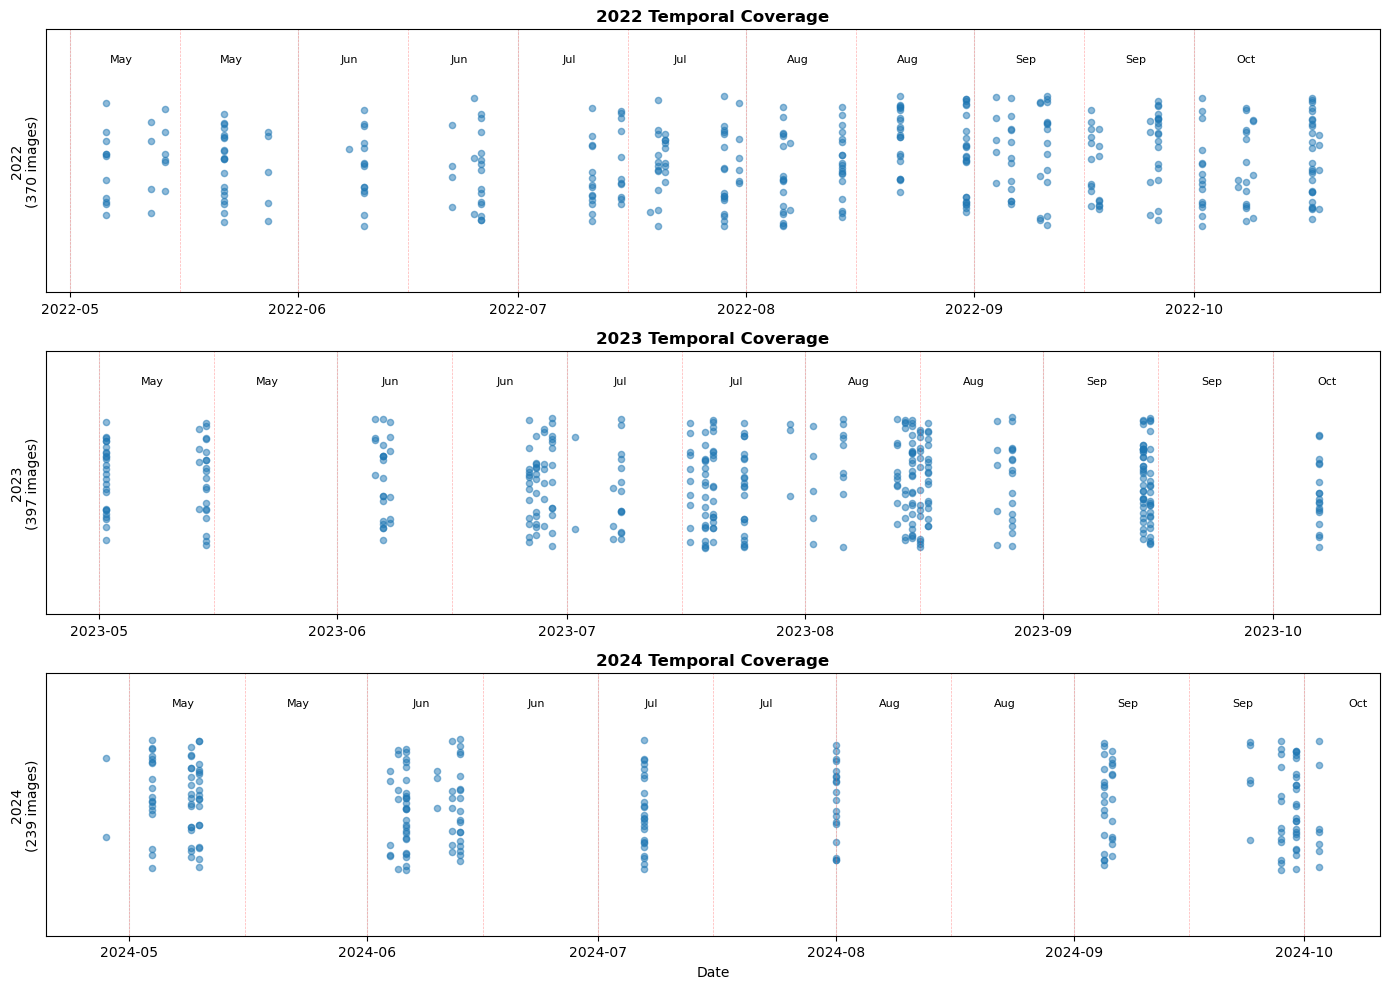


SPATIAL COVERAGE ANALYSIS
✓ Saved: S:\8band_processing_workflow\spatial_coverage.png


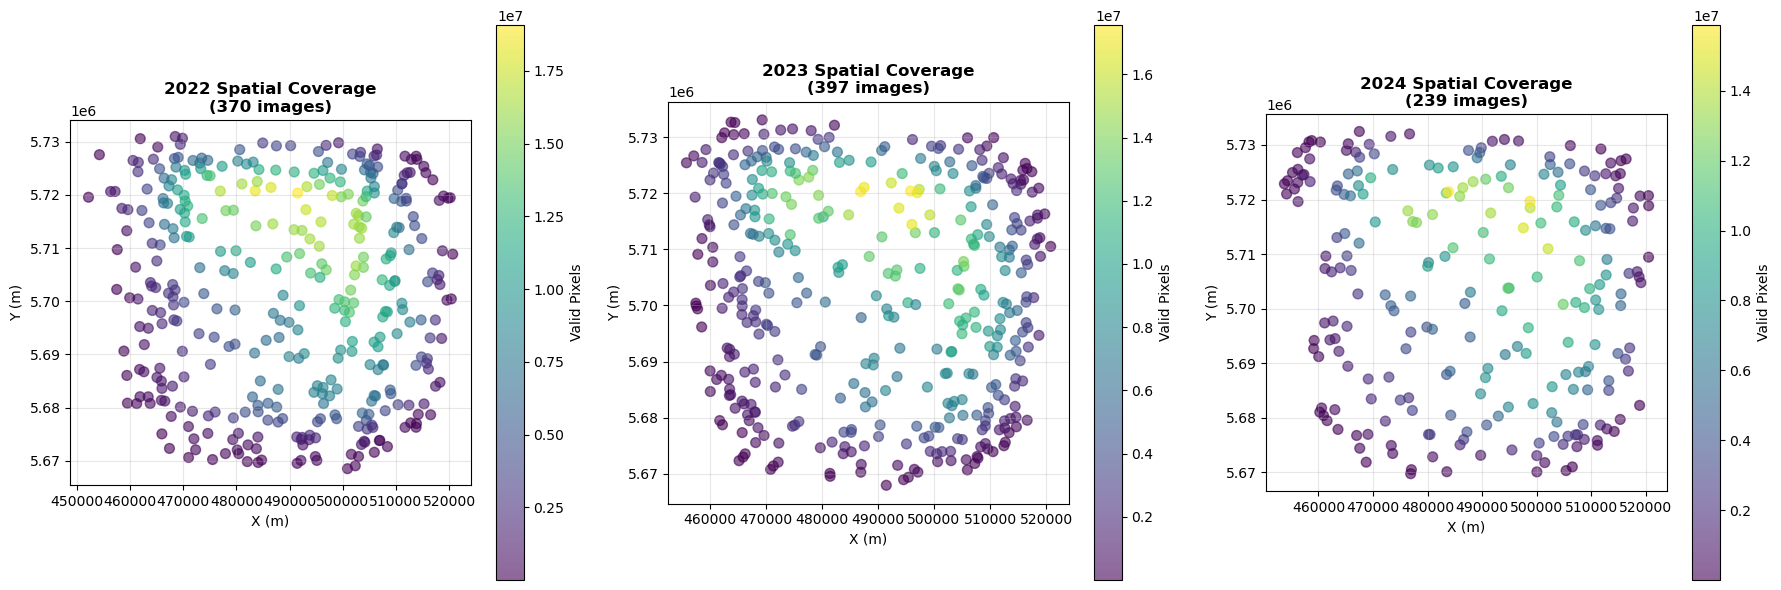


ANALYSIS COMPLETE


In [ ]:
# COMPREHENSIVE TEMPORAL AND SPATIAL COVERAGE CHECK
import pandas as pd
import numpy as np
import rasterio
from datetime import datetime, timedelta
import matplotlib.pyplot as plt

print("="*80)
print("TEMPORAL & SPATIAL COVERAGE ANALYSIS")
print("="*80)

# Define the 11 bi-weekly periods we need for Phase 3
biweekly_periods = [
    ('May 1-15', 5, 1, 5, 15),
    ('May 16-31', 5, 16, 5, 31),
    ('Jun 1-15', 6, 1, 6, 15),
    ('Jun 16-30', 6, 16, 6, 30),
    ('Jul 1-15', 7, 1, 7, 15),
    ('Jul 16-31', 7, 16, 7, 31),
    ('Aug 1-15', 8, 1, 8, 15),
    ('Aug 16-31', 8, 16, 8, 31),
    ('Sep 1-15', 9, 1, 9, 15),
    ('Sep 16-30', 9, 16, 9, 30),
    ('Oct 1-15', 10, 1, 10, 15),
]

def assign_biweekly_period(date):
    """Assign a date to one of the 11 bi-weekly periods"""
    month = date.month
    day = date.day
    
    for period_name, start_month, start_day, end_month, end_day in biweekly_periods:
        if month == start_month and start_day <= day <= end_day:
            return period_name
    return None

# Collect data for all files
all_data = []

for year in [2022, 2023, 2024]:
    year_dir = NDVI_RAW_DIR / str(year)
    ndvi_files = list(year_dir.glob("NDVI_*.tif"))
    
    print(f"\nProcessing {year}: {len(ndvi_files)} files...", end='', flush=True)
    
    for i, ndvi_file in enumerate(ndvi_files):
        if i % 50 == 0:
            print('.', end='', flush=True)
        
        # Extract date from filename: NDVI_YYYYMMDD_...
        parts = ndvi_file.stem.split('_')
        if len(parts) >= 2:
            date_str = parts[1]  # YYYYMMDD
            try:
                date_obj = datetime.strptime(date_str, '%Y%m%d')
                
                # Get spatial info
                with rasterio.open(ndvi_file) as src:
                    bounds = src.bounds
                    ndvi = src.read(1, masked=True)
                    valid_pixels = (~ndvi.mask).sum()
                    
                    # Only include files with valid data
                    if valid_pixels > 0:
                        all_data.append({
                            'year': year,
                            'date': date_obj,
                            'period': assign_biweekly_period(date_obj),
                            'valid_pixels': valid_pixels,
                            'bounds': bounds,
                            'center_x': (bounds.left + bounds.right) / 2,
                            'center_y': (bounds.bottom + bounds.top) / 2
                        })
            except:
                pass
    
    print(' Done!')

df = pd.DataFrame(all_data)

print(f"\n{'='*80}")
print(f"TEMPORAL COVERAGE BY BI-WEEKLY PERIOD")
print(f"{'='*80}")

# Create coverage table
coverage_table = []
for period_name, _, _, _, _ in biweekly_periods:
    row = {'Period': period_name}
    for year in [2022, 2023, 2024]:
        count = len(df[(df['year'] == year) & (df['period'] == period_name)])
        row[str(year)] = count
    coverage_table.append(row)

coverage_df = pd.DataFrame(coverage_table)
print("\nImages per bi-weekly period:")
print(coverage_df.to_string(index=False))

# Summary statistics
print(f"\n{'='*80}")
print("COVERAGE SUMMARY")
print(f"{'='*80}")

for year in [2022, 2023, 2024]:
    year_df = df[df['year'] == year]
    periods_covered = year_df['period'].nunique()
    
    print(f"\n{year}:")
    print(f"  Total usable images: {len(year_df)}")
    print(f"  Bi-weekly periods covered: {periods_covered}/11")
    
    # Check for gaps
    missing_periods = []
    for period_name, _, _, _, _ in biweekly_periods:
        if len(year_df[year_df['period'] == period_name]) == 0:
            missing_periods.append(period_name)
    
    if missing_periods:
        print(f"  ⚠️  Missing periods: {', '.join(missing_periods)}")
    else:
        print(f"  ✓ All periods covered!")
    
    # Min/max images per period
    period_counts = year_df.groupby('period').size()
    if len(period_counts) > 0:
        print(f"  Images per period: {period_counts.min()}-{period_counts.max()} (mean: {period_counts.mean():.1f})")

# Visualize temporal coverage
print(f"\n{'='*80}")
print("CREATING TEMPORAL COVERAGE VISUALIZATION...")
print(f"{'='*80}")

fig, axes = plt.subplots(3, 1, figsize=(14, 10))

for idx, year in enumerate([2022, 2023, 2024]):
    ax = axes[idx]
    year_df = df[df['year'] == year]
    
    # Plot each image as a point
    dates = year_df['date']
    y_vals = np.random.uniform(0.9, 1.1, len(dates))  # Add jitter for visibility
    
    ax.scatter(dates, y_vals, alpha=0.5, s=20)
    
    # Add period boundaries
    for i, (period_name, start_month, start_day, _, _) in enumerate(biweekly_periods):
        period_start = datetime(year, start_month, start_day)
        ax.axvline(period_start, color='red', alpha=0.3, linestyle='--', linewidth=0.5)
        
        # Add period labels at top
        if i < len(biweekly_periods):
            ax.text(period_start + timedelta(days=7), 1.15, 
                   period_name.split()[0], 
                   rotation=0, fontsize=8, ha='center')
    
    ax.set_ylim(0.8, 1.2)
    ax.set_ylabel(f'{year}\n({len(year_df)} images)', fontsize=10)
    ax.set_yticks([])
    ax.grid(True, alpha=0.3)
    ax.set_title(f'{year} Temporal Coverage', fontsize=12, fontweight='bold')

axes[-1].set_xlabel('Date', fontsize=10)
plt.tight_layout()
plt.savefig(BASE_OUTPUT / 'temporal_coverage.png', dpi=150, bbox_inches='tight')
print(f"✓ Saved: {BASE_OUTPUT / 'temporal_coverage.png'}")
plt.show()

# SPATIAL COVERAGE
print(f"\n{'='*80}")
print("SPATIAL COVERAGE ANALYSIS")
print(f"{'='*80}")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for idx, year in enumerate([2022, 2023, 2024]):
    ax = axes[idx]
    year_df = df[df['year'] == year]
    
    # Plot image centers
    scatter = ax.scatter(year_df['center_x'], year_df['center_y'], 
                        c=year_df['valid_pixels'], 
                        cmap='viridis', alpha=0.6, s=50)
    
    ax.set_xlabel('X (m)', fontsize=10)
    ax.set_ylabel('Y (m)', fontsize=10)
    ax.set_title(f'{year} Spatial Coverage\n({len(year_df)} images)', 
                fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.set_aspect('equal')
    
    plt.colorbar(scatter, ax=ax, label='Valid Pixels')

plt.tight_layout()
plt.savefig(BASE_OUTPUT / 'spatial_coverage.png', dpi=150, bbox_inches='tight')
print(f"✓ Saved: {BASE_OUTPUT / 'spatial_coverage.png'}")
plt.show()

print(f"\n{'='*80}")
print("ANALYSIS COMPLETE")
print(f"{'='*80}")